In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
"""
1. Retail Sales Analysis (retail_sales.csv, 1,008 rows)
Question: “Which products, regions, and months drive the most revenue?”
Remove the 8 duplicate orders and fill the missing customer ages.
Create a revenue column from quantity, unit price, and discount.
Plot monthly revenue as a line chart and find the best-selling category.
Show revenue by region and category in a seaborn heatmap.
Compare payment methods with a count plot.
Write a short note on what happens in Nov and Dec.
"""

In [2]:
df1=pd.read_csv("/content/retail_sales.csv")
df1

,order_id,date,category,region,quantity,unit_price,discount_pct,customer_age,payment_method
0,1001,2025-12-11,Clothing,South,4,54.79,0,37.0,Wallet
1,1002,2025-08-17,Home,East,2,90.48,10,18.0,UPI
2,1003,2025-09-07,Home,South,5,71.28,15,30.0,Cash
3,1004,2025-11-24,Groceries,West,4,12.18,5,24.0,UPI
4,1005,2025-07-31,Home,South,2,107.08,20,36.0,Card
...,...,...,...,...,...,...,...,...,...
1003,1369,2025-10-25,Electronics,East,1,247.03,5,35.0,UPI
1004,1243,2025-11-13,Home,South,1,111.41,10,48.0,Cash
1005,1930,2025-10-29,Clothing,North,5,42.86,0,46.0,Cash
1006,1263,2025-11-13,Clothing,West,4,28.27,20,32.0,Card


In [ ]:
df1.shape

(1008, 9)

In [ ]:
df1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1008 entries, 0 to 1007
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   order_id        1008 non-null   int64  
 1   date            1008 non-null   object 
 2   category        1008 non-null   object 
 3   region          1008 non-null   object 
 4   quantity        1008 non-null   int64  
 5   unit_price      1008 non-null   float64
 6   discount_pct    1008 non-null   int64  
 7   customer_age    983 non-null    float64
 8   payment_method  1008 non-null   object 
dtypes: float64(2), int64(3), object(4)
memory usage: 71.0+ KB


In [ ]:
df1.isna().sum()

,0
order_id,0
date,0
category,0
region,0
quantity,0
unit_price,0
discount_pct,0
customer_age,25
payment_method,0


In [ ]:
df1.columns

Index(['order_id', 'date', 'category', 'region', 'quantity', 'unit_price',
       'discount_pct', 'customer_age', 'payment_method', 'revenue'],
      dtype='object')

In [ ]:
df1.duplicated().sum()

np.int64(8)

In [ ]:
df1=df1.drop_duplicates()
df1

,order_id,date,category,region,quantity,unit_price,discount_pct,customer_age,payment_method
0,1001,2025-12-11,Clothing,South,4,54.79,0,37.0,Wallet
1,1002,2025-08-17,Home,East,2,90.48,10,18.0,UPI
2,1003,2025-09-07,Home,South,5,71.28,15,30.0,Cash
3,1004,2025-11-24,Groceries,West,4,12.18,5,24.0,UPI
4,1005,2025-07-31,Home,South,2,107.08,20,36.0,Card
...,...,...,...,...,...,...,...,...,...
995,1996,2025-04-25,Home,South,2,80.26,0,27.0,UPI
996,1997,2025-07-17,Electronics,North,2,374.52,0,27.0,Card
997,1998,2025-06-30,Clothing,North,4,42.64,0,62.0,Wallet
998,1999,2025-01-28,Groceries,West,4,15.29,5,40.0,Wallet


In [ ]:
df1.duplicated().sum()

np.int64(0)

In [ ]:
df1['customer_age'].isna().sum()

np.int64(25)

In [ ]:
df1['customer_age']=df1['customer_age'].fillna(df1['customer_age'].median())
df1

/tmp/ipykernel_2450/1669616340.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df1['customer_age']=df1['customer_age'].fillna(df1['customer_age'].median())


,order_id,date,category,region,quantity,unit_price,discount_pct,customer_age,payment_method
0,1001,2025-12-11,Clothing,South,4,54.79,0,37.0,Wallet
1,1002,2025-08-17,Home,East,2,90.48,10,18.0,UPI
2,1003,2025-09-07,Home,South,5,71.28,15,30.0,Cash
3,1004,2025-11-24,Groceries,West,4,12.18,5,24.0,UPI
4,1005,2025-07-31,Home,South,2,107.08,20,36.0,Card
...,...,...,...,...,...,...,...,...,...
995,1996,2025-04-25,Home,South,2,80.26,0,27.0,UPI
996,1997,2025-07-17,Electronics,North,2,374.52,0,27.0,Card
997,1998,2025-06-30,Clothing,North,4,42.64,0,62.0,Wallet
998,1999,2025-01-28,Groceries,West,4,15.29,5,40.0,Wallet


In [ ]:
df1['customer_age'].isna().sum()

np.int64(0)

In [ ]:
df1['revenue']=(df1['quantity']*df1['unit_price']*(1-df1['discount_pct']/100))
df1

,order_id,date,category,region,quantity,unit_price,discount_pct,customer_age,payment_method,revenue
0,1001,2025-12-11,Clothing,South,4,54.79,0,37.0,Wallet,219.1600
1,1002,2025-08-17,Home,East,2,90.48,10,18.0,UPI,162.8640
2,1003,2025-09-07,Home,South,5,71.28,15,30.0,Cash,302.9400
3,1004,2025-11-24,Groceries,West,4,12.18,5,24.0,UPI,46.2840
4,1005,2025-07-31,Home,South,2,107.08,20,36.0,Card,171.3280
...,...,...,...,...,...,...,...,...,...,...
1003,1369,2025-10-25,Electronics,East,1,247.03,5,35.0,UPI,234.6785
1004,1243,2025-11-13,Home,South,1,111.41,10,48.0,Cash,100.2690
1005,1930,2025-10-29,Clothing,North,5,42.86,0,46.0,Cash,214.3000
1006,1263,2025-11-13,Clothing,West,4,28.27,20,32.0,Card,90.4640


In [ ]:
df1[['quantity','unit_price','discount_pct','revenue']].head()

,quantity,unit_price,discount_pct,revenue
0,4,54.79,0,219.160
1,2,90.48,10,162.864
2,5,71.28,15,302.940
3,4,12.18,5,46.284
4,2,107.08,20,171.328


In [ ]:
# step5
df1['date']=pd.to_datetime(df1['date'])
df1

,order_id,date,category,region,quantity,unit_price,discount_pct,customer_age,payment_method,revenue
0,1001,2025-12-11,Clothing,South,4,54.79,0,37.0,Wallet,219.1600
1,1002,2025-08-17,Home,East,2,90.48,10,18.0,UPI,162.8640
2,1003,2025-09-07,Home,South,5,71.28,15,30.0,Cash,302.9400
3,1004,2025-11-24,Groceries,West,4,12.18,5,24.0,UPI,46.2840
4,1005,2025-07-31,Home,South,2,107.08,20,36.0,Card,171.3280
...,...,...,...,...,...,...,...,...,...,...
1003,1369,2025-10-25,Electronics,East,1,247.03,5,35.0,UPI,234.6785
1004,1243,2025-11-13,Home,South,1,111.41,10,48.0,Cash,100.2690
1005,1930,2025-10-29,Clothing,North,5,42.86,0,46.0,Cash,214.3000
1006,1263,2025-11-13,Clothing,West,4,28.27,20,32.0,Card,90.4640


In [ ]:
df1['Month']=df1['date'].dt.to_period('M')
df1

,order_id,date,category,region,quantity,unit_price,discount_pct,customer_age,payment_method,revenue,Month
0,1001,2025-12-11,Clothing,South,4,54.79,0,37.0,Wallet,219.1600,2025-12
1,1002,2025-08-17,Home,East,2,90.48,10,18.0,UPI,162.8640,2025-08
2,1003,2025-09-07,Home,South,5,71.28,15,30.0,Cash,302.9400,2025-09
3,1004,2025-11-24,Groceries,West,4,12.18,5,24.0,UPI,46.2840,2025-11
4,1005,2025-07-31,Home,South,2,107.08,20,36.0,Card,171.3280,2025-07
...,...,...,...,...,...,...,...,...,...,...,...
1003,1369,2025-10-25,Electronics,East,1,247.03,5,35.0,UPI,234.6785,2025-10
1004,1243,2025-11-13,Home,South,1,111.41,10,48.0,Cash,100.2690,2025-11
1005,1930,2025-10-29,Clothing,North,5,42.86,0,46.0,Cash,214.3000,2025-10
1006,1263,2025-11-13,Clothing,West,4,28.27,20,32.0,Card,90.4640,2025-11


In [ ]:
monthly_revenue = df1.groupby("Month")["revenue"].sum()

monthly_revenue

,revenue
Month,
2025-01,15785.4725
2025-02,15277.6325
2025-03,17903.5490
2025-04,21256.0080
2025-05,19535.9845
2025-06,14863.8155
2025-07,19712.6355
2025-08,19670.9540
2025-09,17190.5490


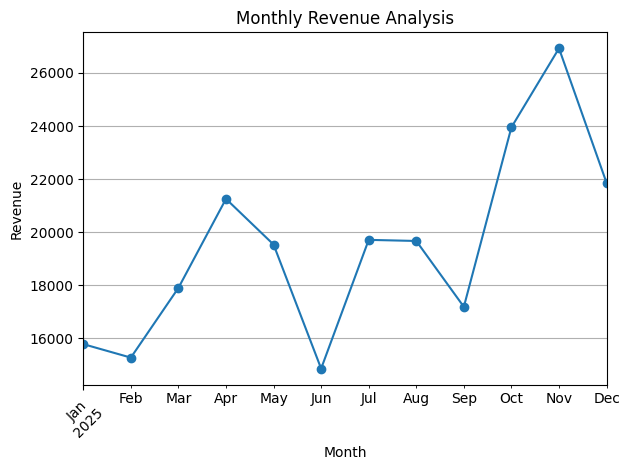

In [ ]:
# create line chart
monthly_revenue.plot(kind="line", marker="o")
plt.title("Monthly Revenue Analysis")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

In [ ]:
# category
category_revenue=df1.groupby('category')['revenue'].sum()
category_revenue.sort_values(ascending=False)

,revenue
category,
Electronics,146058.6825
Clothing,37312.2735
Home,31638.2560
Groceries,11189.3945
Beauty,7735.1290


In [ ]:
category_revenue.idxmax()

'Electronics'

In [ ]:
category_revenue.max()

146058.6825

In [ ]:
df1

,order_id,date,category,region,quantity,unit_price,discount_pct,customer_age,payment_method
0,1001,2025-12-11,Clothing,South,4,54.79,0,37.0,Wallet
1,1002,2025-08-17,Home,East,2,90.48,10,18.0,UPI
2,1003,2025-09-07,Home,South,5,71.28,15,30.0,Cash
3,1004,2025-11-24,Groceries,West,4,12.18,5,24.0,UPI
4,1005,2025-07-31,Home,South,2,107.08,20,36.0,Card
...,...,...,...,...,...,...,...,...,...
1003,1369,2025-10-25,Electronics,East,1,247.03,5,35.0,UPI
1004,1243,2025-11-13,Home,South,1,111.41,10,48.0,Cash
1005,1930,2025-10-29,Clothing,North,5,42.86,0,46.0,Cash
1006,1263,2025-11-13,Clothing,West,4,28.27,20,32.0,Card


In [ ]:
df1['revenue'] = (
    df1['quantity'] * df1['unit_price'] *
    (1 - df1['discount_pct'] / 100)
)
df1

,order_id,date,category,region,quantity,unit_price,discount_pct,customer_age,payment_method,revenue
0,1001,2025-12-11,Clothing,South,4,54.79,0,37.0,Wallet,219.1600
1,1002,2025-08-17,Home,East,2,90.48,10,18.0,UPI,162.8640
2,1003,2025-09-07,Home,South,5,71.28,15,30.0,Cash,302.9400
3,1004,2025-11-24,Groceries,West,4,12.18,5,24.0,UPI,46.2840
4,1005,2025-07-31,Home,South,2,107.08,20,36.0,Card,171.3280
...,...,...,...,...,...,...,...,...,...,...
1003,1369,2025-10-25,Electronics,East,1,247.03,5,35.0,UPI,234.6785
1004,1243,2025-11-13,Home,South,1,111.41,10,48.0,Cash,100.2690
1005,1930,2025-10-29,Clothing,North,5,42.86,0,46.0,Cash,214.3000
1006,1263,2025-11-13,Clothing,West,4,28.27,20,32.0,Card,90.4640


In [ ]:
best_category=df1.groupby('category')['revenue'].sum().idxmax()
print(f"The best-selling category is '{best_category}' with a total revenue of ${category_revenue.max():.2f}.")


The best-selling category is 'Electronics' with a total revenue of $146058.68.


In [ ]:
df1

,order_id,date,category,region,quantity,unit_price,discount_pct,customer_age,payment_method,revenue
0,1001,2025-12-11,Clothing,South,4,54.79,0,37.0,Wallet,219.1600
1,1002,2025-08-17,Home,East,2,90.48,10,18.0,UPI,162.8640
2,1003,2025-09-07,Home,South,5,71.28,15,30.0,Cash,302.9400
3,1004,2025-11-24,Groceries,West,4,12.18,5,24.0,UPI,46.2840
4,1005,2025-07-31,Home,South,2,107.08,20,36.0,Card,171.3280
...,...,...,...,...,...,...,...,...,...,...
1003,1369,2025-10-25,Electronics,East,1,247.03,5,35.0,UPI,234.6785
1004,1243,2025-11-13,Home,South,1,111.41,10,48.0,Cash,100.2690
1005,1930,2025-10-29,Clothing,North,5,42.86,0,46.0,Cash,214.3000
1006,1263,2025-11-13,Clothing,West,4,28.27,20,32.0,Card,90.4640


<Axes: xlabel='category', ylabel='region'>

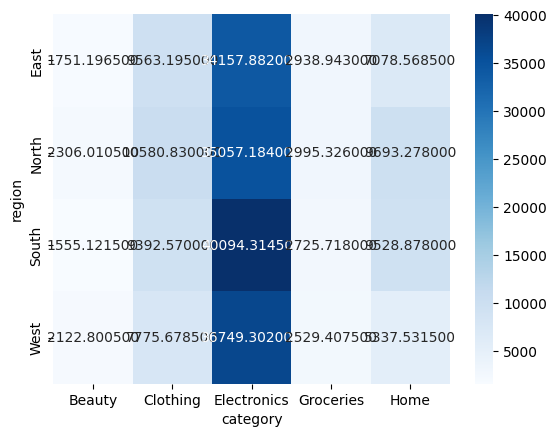

In [ ]:
# task4
pivot=df1.pivot_table(values='revenue',index='region',columns='category',aggfunc='sum')
sns.heatmap(pivot,annot=True,cmap='Blues',fmt='0f')

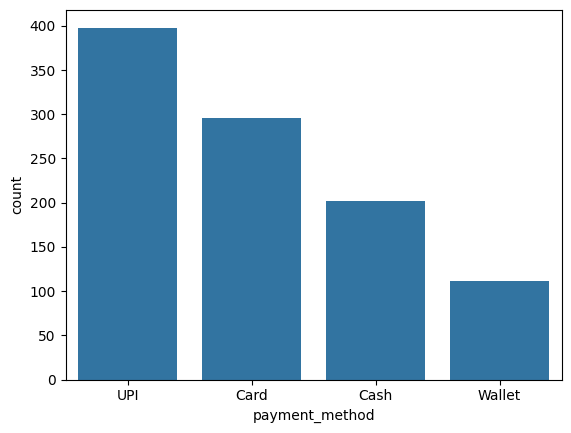

In [ ]:
# task5
sns.countplot(data=df1,x="payment_method",order=df1["payment_method"].value_counts().index)
plt.show()

In [ ]:
df1['date']=pd.to_datetime(df1['date'])
df1

,order_id,date,category,region,quantity,unit_price,discount_pct,customer_age,payment_method,revenue
0,1001,2025-12-11,Clothing,South,4,54.79,0,37.0,Wallet,219.1600
1,1002,2025-08-17,Home,East,2,90.48,10,18.0,UPI,162.8640
2,1003,2025-09-07,Home,South,5,71.28,15,30.0,Cash,302.9400
3,1004,2025-11-24,Groceries,West,4,12.18,5,24.0,UPI,46.2840
4,1005,2025-07-31,Home,South,2,107.08,20,36.0,Card,171.3280
...,...,...,...,...,...,...,...,...,...,...
1003,1369,2025-10-25,Electronics,East,1,247.03,5,35.0,UPI,234.6785
1004,1243,2025-11-13,Home,South,1,111.41,10,48.0,Cash,100.2690
1005,1930,2025-10-29,Clothing,North,5,42.86,0,46.0,Cash,214.3000
1006,1263,2025-11-13,Clothing,West,4,28.27,20,32.0,Card,90.4640


In [ ]:
df1['Month']=df1['date'].dt.to_period('M')
df1

,order_id,date,category,region,quantity,unit_price,discount_pct,customer_age,payment_method,revenue,Month
0,1001,2025-12-11,Clothing,South,4,54.79,0,37.0,Wallet,219.1600,2025-12
1,1002,2025-08-17,Home,East,2,90.48,10,18.0,UPI,162.8640,2025-08
2,1003,2025-09-07,Home,South,5,71.28,15,30.0,Cash,302.9400,2025-09
3,1004,2025-11-24,Groceries,West,4,12.18,5,24.0,UPI,46.2840,2025-11
4,1005,2025-07-31,Home,South,2,107.08,20,36.0,Card,171.3280,2025-07
...,...,...,...,...,...,...,...,...,...,...,...
1003,1369,2025-10-25,Electronics,East,1,247.03,5,35.0,UPI,234.6785,2025-10
1004,1243,2025-11-13,Home,South,1,111.41,10,48.0,Cash,100.2690,2025-11
1005,1930,2025-10-29,Clothing,North,5,42.86,0,46.0,Cash,214.3000,2025-10
1006,1263,2025-11-13,Clothing,West,4,28.27,20,32.0,Card,90.4640,2025-11


In [10]:
print(df1.columns)

Index(['order_id', 'date', 'category', 'region', 'quantity', 'unit_price',
       'discount_pct', 'customer_age', 'payment_method', 'month'],
      dtype='object')


In [13]:
df1['revenue'] = (
    df1['quantity'] * df1['unit_price']
) * (1 - df1['discount_pct'] / 100)

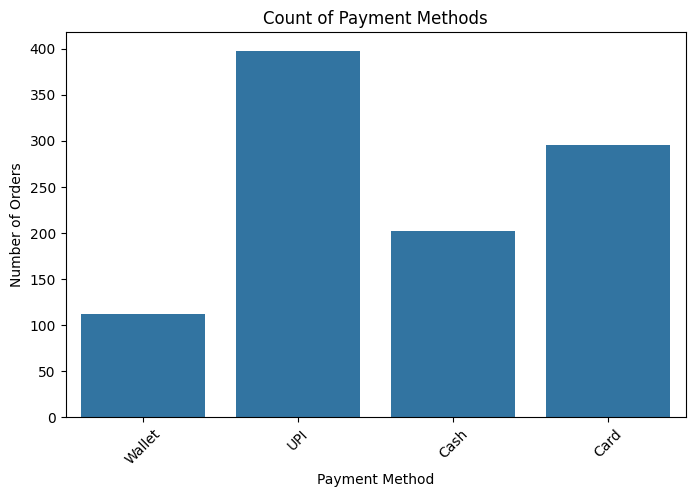

In [14]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df1, x='payment_method')

plt.title('Count of Payment Methods')
plt.xlabel('Payment Method')
plt.ylabel('Number of Orders')
plt.xticks(rotation=45)

plt.show()

month
1     15785.4725
2     15277.6325
3     17903.5490
4     21256.0080
5     19535.9845
6     14863.8155
7     19712.6355
8     19670.9540
9     17190.5490
10    23951.9790
11    26925.6760
12    21859.4800
Name: revenue, dtype: float64
month
11    26925.676
12    21859.480
Name: revenue, dtype: float64


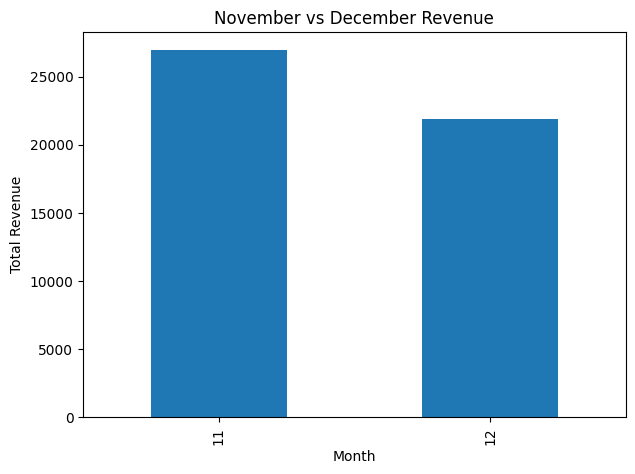

In [15]:
# Convert date column into datetime
df1['date'] = pd.to_datetime(df1['date'])

# Extract month from date
df1['month'] = df1['date'].dt.month

# Calculate monthly revenue
monthly_revenue = df1.groupby('month')['revenue'].sum()

# Print all monthly revenue
print(monthly_revenue)

# November and December revenue
print(monthly_revenue.loc[[11, 12]])

# Plot November vs December
monthly_revenue.loc[[11, 12]].plot(
    kind='bar',
    figsize=(7, 5),
    title='November vs December Revenue'
)

plt.xlabel('Month')
plt.ylabel('Total Revenue')
plt.show()